In [2]:
!wget https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt

--2026-11-16 16:27:39--  https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 198.18.0.231
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|198.18.0.231|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1115394 (1.1M) [text/plain]
Saving to: ‘input.txt’

input.txt           100%[===================>]   1.06M   570KB/s    in 1.9s    

2026-11-16 16:27:42 (570 KB/s) - ‘input.txt’ saved [1115394/1115394]



In [3]:
# read it in to inspect it
with open('input.txt', 'r', encoding='utf-8') as f:
    text = f.read()

In [4]:
print("length of dataset in characters: ", len(text))

length of dataset in characters:  1115394


In [5]:
# let's look at the first 1000 characters
print(text[:1000])

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor citizens, the patricians good.
What authority surfeits on would relieve us: if they
would yield us but the superfluity, while it were
wholesome, we might guess they relieved us humanely;
but they think we are too dear: the leanness that
afflicts us, the object of our misery, is as an
inventory to particularise their abundance; our
sufferance is a gain to them Let us revenge this with
our pikes, ere we become rakes: for the gods know I
speak this in hunger for bread, not in thirst for revenge.



In [6]:
# here are all the unique characters that occur in this text
chars = sorted(list(set(text)))
vocab_size = len(chars)
print(''.join(chars))
print(vocab_size)


 !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz
65


In [7]:
# create a mapping from characters to integers
stoi = { ch:i for i,ch in enumerate(chars) }
itos = { i:ch for i,ch in enumerate(chars) }
encode = lambda s: [stoi[c] for c in s] # encoder: take a string, output a list of integers
decode = lambda l: ''.join([itos[i] for i in l]) # decoder: take a list of integers, output a string

print(encode("hii there"))
print(decode(encode("hii there")))

[46, 47, 47, 1, 58, 46, 43, 56, 43]
hii there


In [8]:
# let's now encode the entire text dataset and store it into a torch.Tensor
import torch # we use PyTorch: https://pytorch.org
data = torch.tensor(encode(text), dtype=torch.long)
print(data.shape, data.dtype)
print(data[:1000]) # the 1000 characters we looked at earier will to the GPT look like this

torch.Size([1115394]) torch.int64
tensor([18, 47, 56, 57, 58,  1, 15, 47, 58, 47, 64, 43, 52, 10,  0, 14, 43, 44,
        53, 56, 43,  1, 61, 43,  1, 54, 56, 53, 41, 43, 43, 42,  1, 39, 52, 63,
         1, 44, 59, 56, 58, 46, 43, 56,  6,  1, 46, 43, 39, 56,  1, 51, 43,  1,
        57, 54, 43, 39, 49,  8,  0,  0, 13, 50, 50, 10,  0, 31, 54, 43, 39, 49,
         6,  1, 57, 54, 43, 39, 49,  8,  0,  0, 18, 47, 56, 57, 58,  1, 15, 47,
        58, 47, 64, 43, 52, 10,  0, 37, 53, 59,  1, 39, 56, 43,  1, 39, 50, 50,
         1, 56, 43, 57, 53, 50, 60, 43, 42,  1, 56, 39, 58, 46, 43, 56,  1, 58,
        53,  1, 42, 47, 43,  1, 58, 46, 39, 52,  1, 58, 53,  1, 44, 39, 51, 47,
        57, 46, 12,  0,  0, 13, 50, 50, 10,  0, 30, 43, 57, 53, 50, 60, 43, 42,
         8,  1, 56, 43, 57, 53, 50, 60, 43, 42,  8,  0,  0, 18, 47, 56, 57, 58,
         1, 15, 47, 58, 47, 64, 43, 52, 10,  0, 18, 47, 56, 57, 58,  6,  1, 63,
        53, 59,  1, 49, 52, 53, 61,  1, 15, 39, 47, 59, 57,  1, 25, 39, 56, 41,
      

In [9]:
# Let's now split up the data into train and validation sets
n = int(0.9*len(data)) # first 90% will be train, rest val
train_data = data[:n]
val_data = data[n:]

In [11]:
block_size = 8 # 上下文
train_data[:block_size+1]

tensor([18, 47, 56, 57, 58,  1, 15, 47, 58])

In [12]:
x = train_data[:block_size]    
y = train_data[1:block_size+1] 
for t in range(block_size):
    context = x[:t+1] # 输入
    target = y[t]     # 预期输出
    print(f"when input is {context} the target: {target}")

when input is tensor([18]) the target: 47
when input is tensor([18, 47]) the target: 56
when input is tensor([18, 47, 56]) the target: 57
when input is tensor([18, 47, 56, 57]) the target: 58
when input is tensor([18, 47, 56, 57, 58]) the target: 1
when input is tensor([18, 47, 56, 57, 58,  1]) the target: 15
when input is tensor([18, 47, 56, 57, 58,  1, 15]) the target: 47
when input is tensor([18, 47, 56, 57, 58,  1, 15, 47]) the target: 58


In [13]:
torch.manual_seed(1337)
batch_size = 4 # how many independent sequences will we process in parallel? 批处理大小
block_size = 8 # what is the maximum context length for predictions?         上下文大小

def get_batch(split):
    # generate a small batch of data of inputs x and targets y
    data = train_data if split == 'train' else val_data
    ix = torch.randint(len(data) - block_size, (batch_size,)) # 随机取一些start index
    x = torch.stack([data[i:i+block_size] for i in ix])       # shape(4, 8)
    y = torch.stack([data[i+1:i+block_size+1] for i in ix])   # shape(4, 8)
    return x, y

xb, yb = get_batch('train')
print('inputs:')
print(xb.shape)
print(xb)
print('targets:')
print(yb.shape)
print(yb)

print('----')

for b in range(batch_size): # batch dimension
    for t in range(block_size): # time dimension
        context = xb[b, :t+1]
        target = yb[b,t]
        print(f"when input is {context.tolist()} the target: {target}")

inputs:
torch.Size([4, 8])
tensor([[24, 43, 58,  5, 57,  1, 46, 43],
        [44, 53, 56,  1, 58, 46, 39, 58],
        [52, 58,  1, 58, 46, 39, 58,  1],
        [25, 17, 27, 10,  0, 21,  1, 54]])
targets:
torch.Size([4, 8])
tensor([[43, 58,  5, 57,  1, 46, 43, 39],
        [53, 56,  1, 58, 46, 39, 58,  1],
        [58,  1, 58, 46, 39, 58,  1, 46],
        [17, 27, 10,  0, 21,  1, 54, 39]])
----
when input is [24] the target: 43
when input is [24, 43] the target: 58
when input is [24, 43, 58] the target: 5
when input is [24, 43, 58, 5] the target: 57
when input is [24, 43, 58, 5, 57] the target: 1
when input is [24, 43, 58, 5, 57, 1] the target: 46
when input is [24, 43, 58, 5, 57, 1, 46] the target: 43
when input is [24, 43, 58, 5, 57, 1, 46, 43] the target: 39
when input is [44] the target: 53
when input is [44, 53] the target: 56
when input is [44, 53, 56] the target: 1
when input is [44, 53, 56, 1] the target: 58
when input is [44, 53, 56, 1, 58] the target: 46
when input is [44, 53

In [22]:
import torch
import torch.nn as nn
from torch.nn import functional as F
torch.manual_seed(1337)

class BigramLanguageModel(nn.Module):

    def __init__(self, vocab_size):
        super().__init__()
        # each token directly reads off the logits for the next token from a lookup table
        # https://docs.pytorch.org/docs/2.15/generated/torch.nn.Embedding.html
        # dim0: num_embeddings (int) – size of the dictionary of embeddings -> 词表有多少个token: 65
        # dim1: embedding_dim (int) – the size of each embedding vector     -> 每个token多少维：65 
        # nn.Embedding.weight 就是 65x65 的矩阵
        # pytorch 自动随机初始化
        self.token_embedding_table = nn.Embedding(vocab_size, vocab_size)
        # idx: 一组输入
        # 如 shape = (4, 8)
        # batch size = 4, block size = 8
        # self.token_embedding_table(idx)
        # 触发forward -> forward(idx) = weight(idx)
        # (4, 8) -> (4, 8, 65)
        

    def forward(self, idx, targets=None):

        # idx and targets are both (B,T) tensor of integers
        logits = self.token_embedding_table(idx) # (B, T, C) -> Batch, Time Steps, Channels 
        # B: batch size 一次forward处理多少个样本
        # T: time steps 上下文长度，每条样本有多少个token (block size)
        # C: channels, 等价于fan_in/fan_out (这里是65)

        if targets is None:
            return logits, None

        # 由于pytorch cross_entropy 参数要求 Input Shape (N, C)
        # https://docs.pytorch.org/docs/2.15/generated/torch.nn.functional.cross_entropy.html
        # 所以要把 (4, 8, 65) reshape到 (32, 65)
        # targets (4, 8) -> (32,)
        B, T, C = logits.shape
        logits = logits.view(-1, 65)
        targets = targets.view(-1)
        loss = F.cross_entropy(logits, targets)

        return logits, loss

    def generate(self, idx, max_new_tokens):
        # idx is (B, T) array of indices in the current context
        for _ in range(max_new_tokens):
            # get the predictions
            logits, _ = self(idx) # (4, 8, 65)
            # focus only on the last time step
            logits = logits[:, -1, :] # (B, T, C) becomes (B, C)   (4,8,65) -> (4,65) 只留最后一个token的分数(biagram model)
            # apply softmax to get probabilities
            probs = F.softmax(logits, dim=-1) # (B, C) 转成概率
            # sample from the distribution
            idx_next = torch.multinomial(probs, num_samples=1) # (B, 1) multinomial按概率随机抽(not argmax)
            # append sampled index to the running sequence
            idx = torch.cat((idx, idx_next), dim=1) # (B, T+1) 把输入加上新预测出的token
        return idx

m = BigramLanguageModel(vocab_size)
print(m.token_embedding_table)
logits, loss = m(xb, yb)
print(logits.shape)
print(loss) # 近似于 -ln(1/65) 无任何信息，均匀猜测

idx = torch.zeros((1,1), dtype=torch.long)
print(decode(m.generate(idx, 100)[0].tolist())) # 未训练：完全随机的输出

Embedding(65, 65)
torch.Size([32, 65])
tensor(4.8786, grad_fn=<NllLossBackward0>)

SKIcLT;AcELMoTbvZv C?nq-QE33:CJqkOKH-q;:la!oiywkHjgChzbQ?u!3bLIgwevmyFJGUGp
wnYWmnxKWWev-tDqXErVKLgJ


In [24]:
# create a PyTorch optimizer
optimizer = torch.optim.AdamW(m.parameters(), lr=1e-3)
# 等价于 反向传播+梯度下降 (SGD)
# AdamW = SGD 加上「动量 + 按每个参数自己的梯度大小缩放学习率 + 权重衰减」？
# for p in parameters:
#     p.grad = None              # ① 清梯度
# loss.backward()                # ② 反向求导
# for p in parameters:
#     p.data += -lr * p.grad     # ③ 沿着梯度挪一步

In [27]:
batch_size = 32
for steps in range(10000): # increase number of steps for good results...

    # sample a batch of data
    xb, yb = get_batch('train')

    # evaluate the loss
    logits, loss = m(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

print(loss.item())

2.4650042057037354


In [28]:
print(decode(m.generate(idx = torch.zeros((1, 1), dtype=torch.long), max_new_tokens=500)[0].tolist()))


ST:
Ma wendwh h t mat fruny f thespr s ancimsll, hanoulaksol to y mppe HER tore, n cad I ders domandavalo pr itheewhimousorendouere t che tofo ixf an.
Whe! olio tifouthand nd athito cameralourgallain My thierinelle atherer, ave re
Hol tainw hy 'sin, yoratheet paprour my t fome;

Thactha e thelowitad,
I ENAn
Fll mp:
loly o u fe,
Wirune s did at hie
IVORo fase's pe will y bet heldu botwomotethacowingig o I ttRiny bjerifr louthiseaseat ss Resth gherct mulenigususunt pincleeacly berd my s.

Theronge


## The mathematical trick in self-attention

In [29]:
torch.manual_seed(1337)

In [30]:
B, T, C = 4, 8, 2
x = torch.randn(B, T, C)
x.shape

torch.Size([4, 8, 2])

In [34]:
# 为了让最新的token包含前面所有信息，取到目前为止的mean作为当前token的输出
# x[b, t] = mean_{i<=t} x[b, i]
xbow = torch.zeros(B, T, C) # bow: bag of words
for b in range(B):
    for t in range(T):
        xprev = x[b, :t+1] # (t, C)
        xbow[b, t] = torch.mean(xprev, dim=0)

In [35]:
x[0]

tensor([[ 0.1808, -0.0700],
        [-0.0894, -0.4926],
        [ 0.2390, -0.1790],
        [ 0.3212, -0.1693],
        [ 0.2026,  0.0514],
        [-0.0826, -0.2283],
        [ 0.1439, -0.1897],
        [-0.0007,  0.0332]])

In [36]:
xbow[0]

tensor([[ 0.1808, -0.0700],
        [ 0.0457, -0.2813],
        [ 0.1101, -0.2472],
        [ 0.1629, -0.2277],
        [ 0.1708, -0.1719],
        [ 0.1286, -0.1813],
        [ 0.1308, -0.1825],
        [ 0.1143, -0.1555]])

In [38]:
# 上述方法效率低，可以用矩阵计算优化
# toy example illustrating how matrix multiplication can be used for a "weighted aggregation"
torch.manual_seed(42)
a = torch.ones(3, 3)
b = torch.randint(0,10,(3,2)).float()
c = a @ b
print('a=')
print(a)
print('--')
print('b=')
print(b)
print('--')
print('c=')
print(c)

a=
tensor([[1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.]])
--
b=
tensor([[2., 7.],
        [6., 4.],
        [6., 5.]])
--
c=
tensor([[14., 16.],
        [14., 16.],
        [14., 16.]])


In [40]:
torch.tril(torch.ones(3,3)) # 返回矩阵（二维张量）或矩阵批次的下三角部分, 结果张量的其他元素设置为 0。

tensor([[1., 0., 0.],
        [1., 1., 0.],
        [1., 1., 1.]])

In [42]:
torch.manual_seed(42)
a = torch.tril(torch.ones(3,3))
b = torch.randint(0,10,(3,2)).float()
c = a @ b
print('a=')
print(a)
print('--')
print('b=')
print(b)
print('--')
print('c=')
print(c)

a=
tensor([[1., 0., 0.],
        [1., 1., 0.],
        [1., 1., 1.]])
--
b=
tensor([[2., 7.],
        [6., 4.],
        [6., 5.]])
--
c=
tensor([[ 2.,  7.],
        [ 8., 11.],
        [14., 16.]])


借助torch.tril, 得到了每列的前缀和。

In [44]:
torch.manual_seed(42)
a = torch.tril(torch.ones(3,3))
a = a / torch.sum(a, 1, keepdim=True) # 把前缀和变成了求mean
b = torch.randint(0,10,(3,2)).float()
c = a @ b
print('a=')
print(a)
print('--')
print('b=')
print(b)
print('--')
print('c=')
print(c)

a=
tensor([[1.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000],
        [0.3333, 0.3333, 0.3333]])
--
b=
tensor([[2., 7.],
        [6., 4.],
        [6., 5.]])
--
c=
tensor([[2.0000, 7.0000],
        [4.0000, 5.5000],
        [4.6667, 5.3333]])


In [45]:
# x (B, T, C)
wei = torch.tril(torch.ones(T, T))
wei = wei / wei.sum(1, keepdim=True)
wei

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3333, 0.3333, 0.3333, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2500, 0.2500, 0.2500, 0.2500, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2000, 0.2000, 0.2000, 0.2000, 0.2000, 0.0000, 0.0000, 0.0000],
        [0.1667, 0.1667, 0.1667, 0.1667, 0.1667, 0.1667, 0.0000, 0.0000],
        [0.1429, 0.1429, 0.1429, 0.1429, 0.1429, 0.1429, 0.1429, 0.0000],
        [0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250]])

In [47]:
x.shape

torch.Size([4, 8, 2])

In [48]:
xbow2 = wei @ x # (T, T) @ (B, T, C) --->  (B, T, T) @ (B, T, C) ---> (B, T, C)
torch.allclose(xbow, xbow2)

True

In [53]:
# use softmax
tril = torch.tril(torch.ones(T, T))
wei = torch.zeros((T,T))
wei = wei.masked_fill(tril == 0, float('-inf')) 
print(wei)
wei = F.softmax(wei, dim=-1) # 对每个元素做 e^x 运算，0->1, -inf->0，再平均
print(wei)

tensor([[0., -inf, -inf, -inf, -inf, -inf, -inf, -inf],
        [0., 0., -inf, -inf, -inf, -inf, -inf, -inf],
        [0., 0., 0., -inf, -inf, -inf, -inf, -inf],
        [0., 0., 0., 0., -inf, -inf, -inf, -inf],
        [0., 0., 0., 0., 0., -inf, -inf, -inf],
        [0., 0., 0., 0., 0., 0., -inf, -inf],
        [0., 0., 0., 0., 0., 0., 0., -inf],
        [0., 0., 0., 0., 0., 0., 0., 0.]])
tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3333, 0.3333, 0.3333, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2500, 0.2500, 0.2500, 0.2500, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2000, 0.2000, 0.2000, 0.2000, 0.2000, 0.0000, 0.0000, 0.0000],
        [0.1667, 0.1667, 0.1667, 0.1667, 0.1667, 0.1667, 0.0000, 0.0000],
        [0.1429, 0.1429, 0.1429, 0.1429, 0.1429, 0.1429, 0.1429, 0.0000],
        [0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250]])


In [50]:
xbow3 = wei @ x
torch.allclose(xbow, xbow3)

True

In [62]:
# version 4: self-attention!
torch.manual_seed(1337)
B,T,C = 4,8,32 # batch, time, channels
x = torch.randn(B,T,C)

# let's see a single Head perform self-attention
head_size = 16

# key 把token投影到一个空间 ----- “我能提供什么” what do i contain
key = nn.Linear(C, head_size, bias=False)   # (16, 32) <- weight 存的是 (fan_out, fan_in)

# query 把token投影到一个空间 ---- “我要找什么” what do i looking for
query = nn.Linear(C, head_size, bias=False) 

# 我(token)的query和其他(token)的key做点积(dot product)
# 点积越大 -> 我会更多地从你那里取信息（注意力分配）

# value "如果你对我感兴趣，这是我能传达给你的信息"
# 区分k和v:
# k: 我是个代词
# v: 我指向前文的猫
value = nn.Linear(C, head_size, bias=False)

k = key(x)   # (B, T, 16)  
q = query(x) # (B, T, 16)
wei =  q @ k.transpose(-2, -1) # (B, T, 16) @ (B, 16, T) ---> (B, T, T) 
# wei得到了每个q和k之间的亲和力(affinity)
# wei[b, i, j] = q[b,i] * k[b,j]
# b：哪条样本
# i: 谁在query
# j: 谁被query
# 总结：
# x是(4,8,32) 32维投影到16维的key和query，key和query做矩阵乘法，得到wei (4,8,8) ，
# 如wei[0][0][3], 代表第1个样本的第1个token对第4个token的亲和力
# 得到了亲和力原始分数（未经mask+softmax）
# 经mask+softmax后
# wei[0][0][3] = 0，因为第1个token只能看到自己，即它对后面token注意力为0

tril = torch.tril(torch.ones(T, T))
wei = wei.masked_fill(tril == 0, float('-inf'))
wei = F.softmax(wei, dim=-1)

v = value(x)
out = wei @ v

out.shape

torch.Size([4, 8, 16])

In [57]:
wei[0]

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.1574, 0.8426, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2088, 0.1646, 0.6266, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5792, 0.1187, 0.1889, 0.1131, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.0294, 0.1052, 0.0469, 0.0276, 0.7909, 0.0000, 0.0000, 0.0000],
        [0.0176, 0.2689, 0.0215, 0.0089, 0.6812, 0.0019, 0.0000, 0.0000],
        [0.1691, 0.4066, 0.0438, 0.0416, 0.1048, 0.2012, 0.0329, 0.0000],
        [0.0210, 0.0843, 0.0555, 0.2297, 0.0573, 0.0709, 0.2423, 0.2391]],
       grad_fn=<SelectBackward0>)

从列看：其他token对该token的注意力  
从行看：当前token对其他token的注意力

多头：  
head_size: 维度： 每个头里 q/k/v 向量的长度  
n_head: 个数： 并行几套 q/k/v  

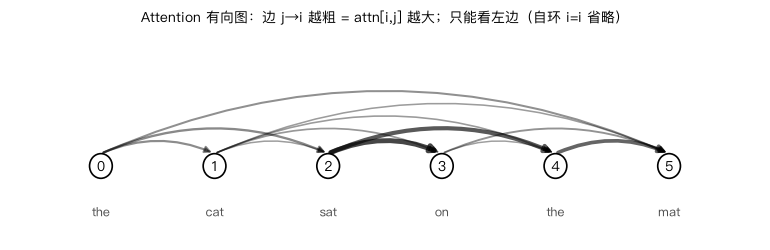

In [65]:
"""Attention 的有向图（只画因果 mask 下的正确情况）。
节点 = token，排成一行；边 j -> i 表示「位置 i 从位置 j 取信息」，
只允许 j <= i（看不到未来），边越粗 = attn[i, j] 越大。（自环 i==i 为清晰省略。）"""

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from matplotlib.patches import FancyArrowPatch, Circle

plt.rcParams["font.sans-serif"] = ["PingFang SC", "Heiti TC", "DejaVu Sans"]

# ---------- 1. 一个真实的因果注意力 attn (T, T)，每行和为 1 ----------
T = 6
tokens = ["the", "cat", "sat", "on", "the", "mat"]
torch.manual_seed(1)
x = torch.randn(1, T, 16)
Wq, Wk = torch.randn(16, 8) / 4, torch.randn(16, 8) / 4
wei = (x @ Wq) @ (x @ Wk).transpose(-2, -1) * 8 ** -0.5                  # 原始分数
wei = wei.masked_fill(torch.tril(torch.ones(T, T)) == 0, float("-inf"))  # 因果 mask
attn = F.softmax(wei, dim=-1)[0].numpy()

# ---------- 2. 画图 ----------
fig, ax = plt.subplots(figsize=(T * 1.3, 2.6))
r, thresh = 0.1, 0.06

for i in range(T):
   ax.add_patch(Circle((i, 0), r, fc="white", ec="black", lw=1.2, zorder=3))
   ax.text(i, 0, str(i), ha="center", va="center", fontsize=10, zorder=4)
   ax.text(i, -0.32, tokens[i], ha="center", va="top", fontsize=9, color="0.3")

for i in range(T):
   for j in range(i):                  # 只画 j < i：过去 -> 现在（自环省略）
       w = attn[i, j]
       if w < thresh:
           continue
       ax.add_patch(FancyArrowPatch(
           (j, r), (i, r),
           connectionstyle="arc3,rad=-0.22",
           arrowstyle="-|>", mutation_scale=10,
           lw=0.5 + 5 * w, color="black", alpha=0.3 + 0.7 * w, zorder=2))

ax.set_xlim(-0.8, T - 0.2)
ax.set_ylim(-0.6, 1.1)
ax.axis("off")
ax.set_title("Attention 有向图：边 j→i 越粗 = attn[i,j] 越大；只能看左边（自环 i=i 省略）",
            fontsize=10)
plt.tight_layout()
plt.show()

 - 注意力是一种通信机制。它可以被视为有向图中的各个节点在相互“注视”；每个节点通过加权求和的方式，汇聚来自所有指向自身的节点所提供的信息，其中权重取决于数据本身。
   - 假设有4个batch, 8个node(对应一个字符, 上图只是方便理解写成单词)，那么有4个独立的图，每个图8个节点互相通信。
 - 这里不存在“空间”的概念。注意力机制仅仅是作用于一组向量之上。正因如此，我们需要对标记（token）进行位置编码。  
 - 批次维度中的每个样本显然都是完全独立处理的，它们之间绝不会有任何“交流”。  
 - 在“编码器”（encoder）注意力模块中，只需删掉那行使用 `tril`（下三角矩阵）进行掩码操作的代码，即可让所有词元（token）之间都能进行交互。此处展示的模块被称为“解码器”（decoder）注意力模块，因为它包含三角掩码机制；该模块通常用于自回归（autoregressive）场景，例如语言建模。
   - 语言建模中要求【未来不可见】，别的场景可能允许，如【情感分析】
 - “自注意力”（self-attention）是指键（keys）和值（values）与查询（queries）源自同一来源。而在“交叉注意力”（cross-attention）中，查询依然由 x 生成，但键和值则来自另一个外部来源（例如编码器模块）。
 - “缩放”（Scaled）注意力机制额外将权重（wei）除以 $\sqrt{\text{head\_size}}$。这样，当输入 $Q$ 和 $K$ 的方差为 1 时，权重（wei）的方差也将保持为 1，从而使 Softmax 的输出分布更为平缓，避免出现过度饱和的情况。


In [69]:
k = torch.randn(B,T,head_size)
q = torch.randn(B,T,head_size)
wei = q @ k.transpose(-2, -1) * head_size**-0.5 # 除以 根号(head_size)，防止softmax出现one-hot
print(k.var(), q.var(), wei.var())

tensor(1.0299) tensor(1.0517) tensor(1.0791)
